# Initialisation
Code below is for preppring tools for use

---

In [1]:
# import plotting tools
# plotnine is the python clone of ggplot2 from R
# this should be used over plt where possible

import pandas as pd
import matplotlib as plt
from plotnine import *
import numpy as np

In [2]:
from collections import *
from skimage import *
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
from transformers import AutoTokenizer, pipeline, AutoModel
import torch
import re
from thefuzz import process

# Testing
The code below is for the testing of basic premise and ideas, such as probing raw statistics and the like. This may also be used for getting familuar with certain tools and datasets.

In [4]:
df = pd.read_csv('att_sch_stats/att_sch.csv')

attainment_2025 = df[df['DateCode'].astype(str).str.contains("2024-25", na=False)]
above_5_2025 = attainment_2025[
    (
        attainment_2025['Number Of Awards'].astype(str).str.contains("5", na=False)
    ) & (
        attainment_2025['SCQF Level'].astype(str).str.contains("6", na=False)
    )
]
att_list = above_5_2025[["GeographyName", "Value"]]
att_list = att_list.sort_values(by="GeographyName")
att_list = att_list[att_list.GeographyName != "National"]

supressors = ["*", "#"]

supressed_schools = att_list[
    att_list["Value"].astype(str).isin(supressors)
].sort_values(by="GeographyName")

att_list = att_list[
    ~att_list["Value"].astype(str).isin(supressors)
].copy()

att_list

,GeographyName,Value
155091,Aberdeen Grammar School,72
155511,Aboyne Academy,46
171891,Airdrie Academy,35
154111,Alford Academy,41
169511,All Saints Secondary School,38
...,...,...
171261,Whitehill Secondary School,22
151241,Wick High School,18
174131,Williamwood High School,82
174061,Woodfarm High School,74


In [29]:
target = "Value"
primary_ys = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]
features = [
    "SIMD Quintile 1 [Note 6]"
]
supressed_schools

,GeographyName,Value
165171,Aith Junior High School,#
165241,Baltasound Junior High School,#
165661,Castlebay School,*
164051,Dalry Secondary School,#
168041,Doon Academy,*
150541,Grant Aided,*
165941,Islay High School,*
152431,Kilchuimen Academy,*
153131,Kinlochbervie High School,*
152221,Kinlochleven High School,*


In [5]:
sch_sum_2025 = pd.read_excel('sch_sum_stats/sch_sum_2025.xlsx', sheet_name=2, header=1)
hs_sum_2025 = sch_sum_2025[sch_sum_2025["School Type"].astype(str).str.contains("Secondary")]
hs_sum_2025 = hs_sum_2025.drop(columns=primary_ys).drop(columns="Special school pupils")
hs_sum_2025 = hs_sum_2025.sort_values(by="School Name")
hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(["Braeview Academy", "Craigie High School", "Glasgow Gaelic School", "St Joseph's Academy", "The Community School of Auchterarder"])]

supressed_names = supressed_schools["GeographyName"].to_list()
pattern = '|'.join(re.escape(name) for name in supressed_names)
hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).str.contains(pattern, case=False)].copy()

# hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(supressed_schools["GeographyName"])].copy()
# hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"])]
att_list = att_list[att_list["GeographyName"].astype(str).isin(hs_sum_2025["School Name"].astype(str))].copy()
hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"].astype(str))].copy()

NameError: name 'primary_ys' is not defined

In [12]:
hs_sum_2025

,Local Authority,SeedCode,School Name,School Type,Teachers (Full Time Equivalent) [Note 1],Pupil roll,Pupil Teacher Ratio,Average class size,Female,Male,...,SIMD Quintile 4 [Note 6],SIMD Quintile 5 [Note 6],SIMD not availble [Note 6],Urban [Note 7],Small town [Note 7],Rural [Note 7],Urban/rural classification not available [Note 7],School's 6-fold urban/rural classification,School's 8-fold urban/rural classification,Denomination of school
6,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,113.6,1369,12.1,0,684,685,...,211,714,0,90 - 100%,0 - 10%,0 - 10%,NaN,Large urban areas,Large urban areas,Non-denominational school
19,Aberdeenshire,5257530,Aboyne Academy,Secondary,55.8,631,11.3,0,301,330,...,352,244,0,NaN,0 - 10%,90 - 100%,NaN,Remote rural areas,Remote rural areas,Non-denominational school
27,North Lanarkshire,8505438,Airdrie Academy,Secondary,77.5,1018,13.1,0,508,510,...,147,19,0,80 - 90%,0 - 10%,10 - 20%,NaN,Large urban areas,Large urban areas,Non-denominational school
39,Aberdeenshire,5230934,Alford Academy,Secondary,58.9,689,11.7,0,337,352,...,308,315,0,0 - 10%,0 - 10%,90 - 100%,NaN,Accessible rural areas,Accessible rural areas,Non-denominational school
43,Glasgow City,8431930,All Saints Secondary School,Secondary,70,955,13.6,0,487,468,...,40,16,3,90 - 100%,0 - 10%,0 - 10%,0 - 10%,Large urban areas,Large urban areas,Roman Catholic school
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2391,Glasgow City,8439532,Whitehill Secondary School,Secondary,62.2,651,10.5,0,309,342,...,20,7,0,90 - 100%,0 - 10%,NaN,NaN,Large urban areas,Large urban areas,Non-denominational school
2400,Highland,5102138,Wick High School,Secondary,58.5,719,12.3,0,374,345,...,143,0,0,NaN,50 - 60%,40 - 50%,NaN,Remote small towns,Very remote Small towns,Non-denominational school
2404,East Renfrewshire,8602034,Williamwood High School,Secondary,137.9,1664,12.1,0,847,817,...,215,1329,0,90 - 100%,0 - 10%,0 - 10%,NaN,Large urban areas,Large urban areas,Non-denominational school
2417,East Renfrewshire,8601836,Woodfarm High School,Secondary,72.5,686,9.5,0,336,350,...,147,346,0,90 - 100%,0 - 10%,0 - 10%,NaN,Large urban areas,Large urban areas,Non-denominational school


In [13]:
att_list

,GeographyName,Value
155091,Aberdeen Grammar School,72
155511,Aboyne Academy,46
171891,Airdrie Academy,35
154111,Alford Academy,41
169511,All Saints Secondary School,38
...,...,...
171261,Whitehill Secondary School,22
151241,Wick High School,18
174131,Williamwood High School,82
174061,Woodfarm High School,74


In [30]:
x = hs_sum_2025[features]
y = att_list[target]

numeric_features = features

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [32]:
model = Pipeline([
    ("Preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        random_state=42
    ))
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

ValueError: Cannot use median strategy with non-numeric data:
could not convert string to float: 'c'

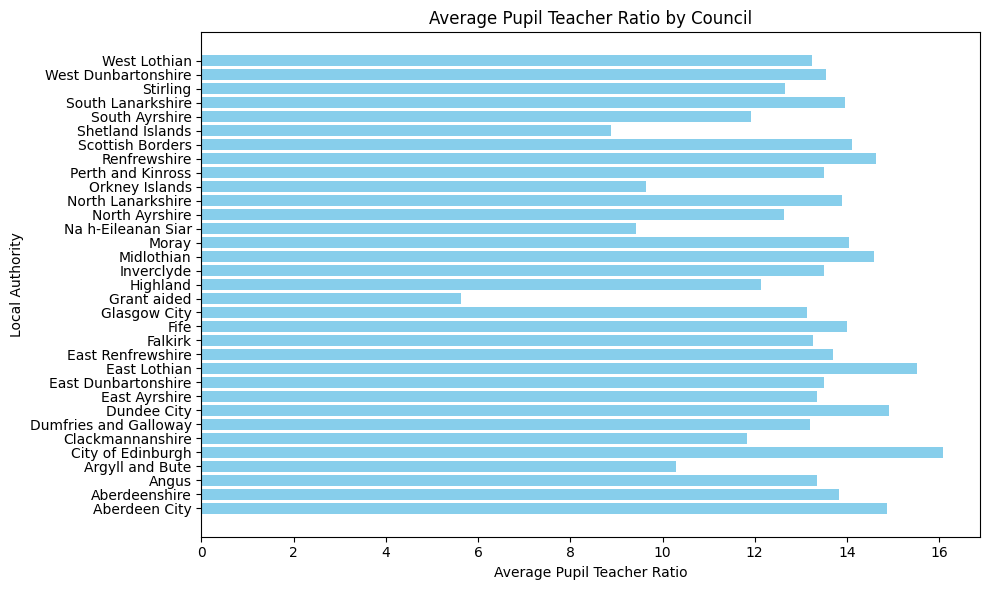

In [ ]:
# import matplotlib.pyplot as plt

# # 1. Calculate average Pupil Teacher Ratio per council
# avg_ptr = db.groupby("Local Authority")["Pupil Teacher Ratio"].mean().reset_index()

# # 2. Create figure and axes object properly
# fig, ax = plt.subplots(figsize=(10, 6))

# # 3. Plot a horizontal bar chart
# ax.barh(avg_ptr["Local Authority"], avg_ptr["Pupil Teacher Ratio"], color="skyblue")

# ax.set_xlabel("Average Pupil Teacher Ratio")
# ax.set_ylabel("Local Authority")
# ax.set_title("Average Pupil Teacher Ratio by Council")

# plt.tight_layout()
# plt.show()